# EDA и бинарная классификация на датасете «Титаник»

## Титульный лист

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 1:** Введение в Data Science и EDA  
**Датасет:** *Titanic — Machine Learning from Disaster*

**Выполнил:** Белозёров Константин Сергеевич  
**Группа:** ПКТб-23-1  
**Преподаватель:** не указан в задании

**Ссылка на репозиторий:** https://github.com/Pankyxa/ML_Spirin  
**Путь к модулю:** `module-1-titanic/notebook.ipynb`  
**Дата сдачи:** 2026-11-02

*При подготовке ноутбука использовался ИИ-ассистент Cursor. Все числа ниже получены запуском кода на `train.csv`, а не взяты из чужого kernel.*


## Введение

**Задача.** По данным о пассажире «Титаника» нужно предсказать, выжил он или нет. Это бинарная классификация: `Survived = 0` — не выжил, `Survived = 1` — выжил. Модель не восстанавливает точное время или номер шлюпки, а относит человека к одному из двух классов.

**Что такое ML-проект.** Это не один вызов `fit`. Сначала данные осматривают и чистят, затем собирают признаки, обучают несколько моделей, сравнивают их на отложенной выборке и только после этого сохраняют ту, которой можно пользоваться. Если пропустить разведку, легко заполнить пропуски «в среднем» и не заметить, что возраст зависит от класса билета.

**Почему это классификация, а не регрессия.** Регрессия предсказывает непрерывное число: цену, температуру, время. Здесь ответ — метка из конечного набора {0, 1}. У логистической регрессии на выходе всё равно есть число, но это вероятность класса, а итоговое решение — порог 0.5. Оценивать такую модель через MSE было бы странно: ошибка «предсказал 0.1 вместо 0» и ошибка «перепутал живого с погибшим» для задачи имеют разный смысл, поэтому нужны метрики классификации.

**Какая метрика важнее.** Классы неравны: погибло 61.6% пассажиров, выжило 38.4%. Accuracy легко завысить, если почти всех записывать в «не выжил». Precision показывает, насколько предсказание «выживет» чистое, recall — какую долю реально выживших модель нашла. F1 сводит их вместе. Для сравнения моделей в этой работе главная метрика — **ROC-AUC**: она не привязана к одному порогу и показывает, отделяет ли модель выживших от погибших по вероятности. Цель по заданию — ROC-AUC не ниже 0.80.

**Цель работы:**

1. Провести полный EDA датасета «Титаник» и зафиксировать, какие признаки связаны с выживанием.
2. Обучить минимум две модели (логистическую регрессию и дерево решений) и достичь ROC-AUC ≥ 0.80.
3. Реализовать функцию `predict_passenger` для нового пассажира и проверить её на нескольких разных профилях.


## Теоретическая часть

### EDA

EDA (exploratory data analysis) — это осмотр таблицы до обучения. Сначала смотрят размеры, типы и пропуски, потом распределения и связь признаков с целью. Графики здесь нужны не для красоты: по ним решают, что делать с хвостами, редкими категориями и пропусками. Если этот шаг пропустить, модель может выучить артефакт вроде номера билета или «среднего возраста», которого в данных на самом деле нет. В этой работе EDA отвечает на конкретный вопрос: кто на «Титанике» выживал чаще и какие столбцы вообще можно отдать в модель.

### Пропуски

`NaN` появляется, когда значение не записали, его не было или поле неприменимо. На «Титанике» возраст не указан у каждого пятого, каюта — у трёх четвертей, порт посадки — у двух человек. Удалять строки с пустым возрастом жалко: теряется почти 20% выборки, и пропуски могут быть не случайными (например, чаще у пассажиров третьего класса). Поэтому возраст заполняется медианой внутри группы «класс + пол»: медиана устойчива к долгожителям из первого класса, а группа учитывает, что женщины и пассажиры первого класса в среднем старше. Два пропуска в `Embarked` закрываются модой — самой частой гаванью. Столбец `Cabin` удаляется: при 77% пустых ячеек номер каюты без отдельной обработки палубы больше шумит, чем помогает.

### Кодирование категорий

Линейная модель и дерево из scikit-learn ждут числа. **Label Encoding** ставит категории в соответствие числам 0, 1, 2… Он уместен для пола, где значений два, но для неупорядоченного признака с тремя и более уровнями числа создают ложный порядок. **One-Hot Encoding** заводит отдельный столбец на каждую категорию: 1, если она встретилась, иначе 0. Так кодируется порт посадки. Один столбец (`Embarked_C`) оставляется базовым уровнем и в матрицу признаков не входит, иначе столбцы дамми в сумме дают единицу и дублируют свободный член.

### Масштабирование

**StandardScaler** вычитает среднее и делит на стандартное отклонение, то есть приводит признак к масштабу «сколько сигм от среднего». **MinMaxScaler** сжимает признак в отрезок, обычно [0, 1], и сильнее реагирует на один огромный выброс. Логистической регрессии масштаб нужен: штраф L2 и градиентный спуск сравнивают коэффициенты, а возраст измеряется десятками, стоимость билета — сотнями. Дереву масштаб не нужен: оно режет по порогу и сравнивает только порядок значений внутри одного столбца. Поэтому scaler обучается только для логистической регрессии и только на обучающей части, без тестовых строк.

### Feature Engineering

Новый признак — это не «ещё столбец», а формулировка гипотезы, которой нет в сырой таблице. `SibSp` и `Parch` по отдельности плохо говорят, был ли человек один. Сумма `Family_Size = SibSp + Parch + 1` собирает размер семьи, а `Is_Alone` прямо кодирует гипотезу «одиночке некому помочь». `Age_Group` режет возраст на понятные корзины, чтобы увидеть детей отдельно от средних возрастов: линейный коэффициент возраста этого излома не покажет. Плохой новый признак (номер билета, сырой `PassengerId`) модель тоже с радостью использует, поэтому каждый столбец нужно уметь объяснить.

### Метрики классификации

Считаем по матрице ошибок. **TP** — верно найденный выживший, **TN** — верно найденный погибший, **FP** — погибшего назвали выжившим, **FN** — выжившего пропустили.

$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$

$$Precision = \frac{TP}{TP + FP} \qquad Recall = \frac{TP}{TP + FN}$$

$$F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$$

Accuracy — доля любых верных ответов. Precision — доля настоящих выживших среди тех, кого модель записала в выжившие. Recall — доля найденных выживших. F1 падает, если одна из этих двух величин близка к нулю. ROC-AUC — площадь под кривой, где по оси X доля ложных тревог (FPR), а по оси Y доля найденных выживших (TPR). AUC = 0.5 означает угадывание, AUC = 1 — идеальное ранжирование. В отчёте ROC-AUC считается по вероятностям, а не по жёстким меткам 0/1.

| Этап | Зачем | Что делаем в этой работе |
|------|--------|---------------------------|
| Осмотр | Понять типы, пропуски, баланс | `shape`, `info`, `describe`, доли классов |
| Картинки | Увидеть связь с `Survived` | countplot, гистограмма, boxplot, heatmap, barplot |
| Чистка | Не учить модель на дырках | медиана возраста по группе, мода порта, удаление `Cabin` |
| Признаки | Закодировать гипотезы | семья, одиночество, пол, дамми порта |
| Обучение | Сравнить линейную и древесную модель | Logistic Regression и Decision Tree |
| Проверка | Не верить одной accuracy | precision, recall, F1, ROC-AUC, матрица ошибок |


## Описание данных

**Источник:** [Titanic — Machine Learning from Disaster](https://www.kaggle.com/c/titanic)

Обучающая таблица — 891 пассажир, тестовая Kaggle — 418 пассажиров без столбца `Survived`. В обучении 11 исходных признаков и целевая метка. Числовых столбцов 7 (`PassengerId`, `Survived`, `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`), категориальных 5 (`Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`). `PassengerId`, `Name` и `Ticket` в модель не идут: это идентификаторы, а не свойства, из-за которых человека сажали в шлюпку.

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| PassengerId | int64 | ID пассажира | 0 (0%) |
| Survived | int64 (0/1) | Целевая: выжил или нет | 0 (0%) |
| Pclass | int64 (1/2/3) | Класс билета | 0 (0%) |
| Name | object | Имя | 0 (0%) |
| Sex | object | Пол | 0 (0%) |
| Age | float64 | Возраст | 177 (19.9%) |
| SibSp | int64 | Братья, сёстры, супруги | 0 (0%) |
| Parch | int64 | Родители и дети | 0 (0%) |
| Ticket | object | Номер билета | 0 (0%) |
| Fare | float64 | Цена билета | 0 (0%) |
| Cabin | object | Каюта | 687 (77.1%) |
| Embarked | object | Порт посадки | 2 (0.2%) |

**Распределение классов в train:**

- Не выжило (0): 549 (61.6%)
- Выжило (1): 342 (38.4%)

**Файл данных в репозитории:** `module-1-titanic/data/titanic_info.md`

Код ниже заново читает CSV и печатает размеры, чтобы цифры в тексте можно было сверить.


In [1]:
%matplotlib inline

# Библиотеки раздела: таблица, графики и вывод датафреймов в ноутбуке
import json
import time
from io import BytesIO

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Единый стиль картинок и читаемая кириллица на осях
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.unicode_minus"] = False

# Относительные пути: ноутбук запускается из папки module-1-titanic
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

# Обязательная проверка формы обеих выборок
print(train_df.shape, test_df.shape)

# Доля каждого класса: дисбаланс виден уже здесь
class_counts = train_df["Survived"].value_counts().sort_index()
class_share = train_df["Survived"].value_counts(normalize=True).sort_index()
print("Класс 0:", int(class_counts[0]), f"({class_share[0]:.1%})")
print("Класс 1:", int(class_counts[1]), f"({class_share[1]:.1%})")


(891, 12) (418, 11)
Класс 0: 549 (61.6%)
Класс 1: 342 (38.4%)


## Подготовка данных и EDA

Сырой `train.csv` сначала осматривается целиком: типы, пропуски, сдвиг и хвосты распределений. Графики строятся **до** заполнения пропусков, чтобы дырки в возрасте не прятались за медианой. После выводов таблица копируется, чистится и только потом превращается в матрицу признаков.


In [2]:
# Первые строки: имена, пол, класс и пустая каюта у третьего класса
display(train_df.head())

# Типы и число непустых значений по столбцам
train_df.info()

# Среднее, квантили и максимумы. Fare сильно тянет максимум
display(train_df.describe())

# Абсолютные пропуски и доля от 891 строки
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_table = pd.DataFrame({"пропуски": missing, "доля_%": missing_pct})
display(missing_table)

# Асимметрия и эксцесс числовых признаков. Большой skew у Fare — длинный правый хвост
numeric_for_shape = ["Age", "Fare", "SibSp", "Parch"]
print("Асимметрия:")
print(train_df[numeric_for_shape].skew().round(3))
print("Эксцесс:")
print(train_df[numeric_for_shape].kurtosis().round(3))

# Как часто встречаются пол, класс и порт
print("Пол:")
print(train_df["Sex"].value_counts())
print("Класс:")
print(train_df["Pclass"].value_counts().sort_index())
print("Порт:")
print(train_df["Embarked"].value_counts(dropna=False))


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,пропуски,доля_%
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


Асимметрия:
Age      0.389
Fare     4.787
SibSp    3.695
Parch    2.749
dtype: float64
Эксцесс:
Age       0.178
Fare     33.398
SibSp    17.880
Parch     9.778
dtype: float64
Пол:
Sex
male      577
female    314
Name: count, dtype: int64
Класс:
Pclass
1    216
2    184
3    491
Name: count, dtype: int64
Порт:
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


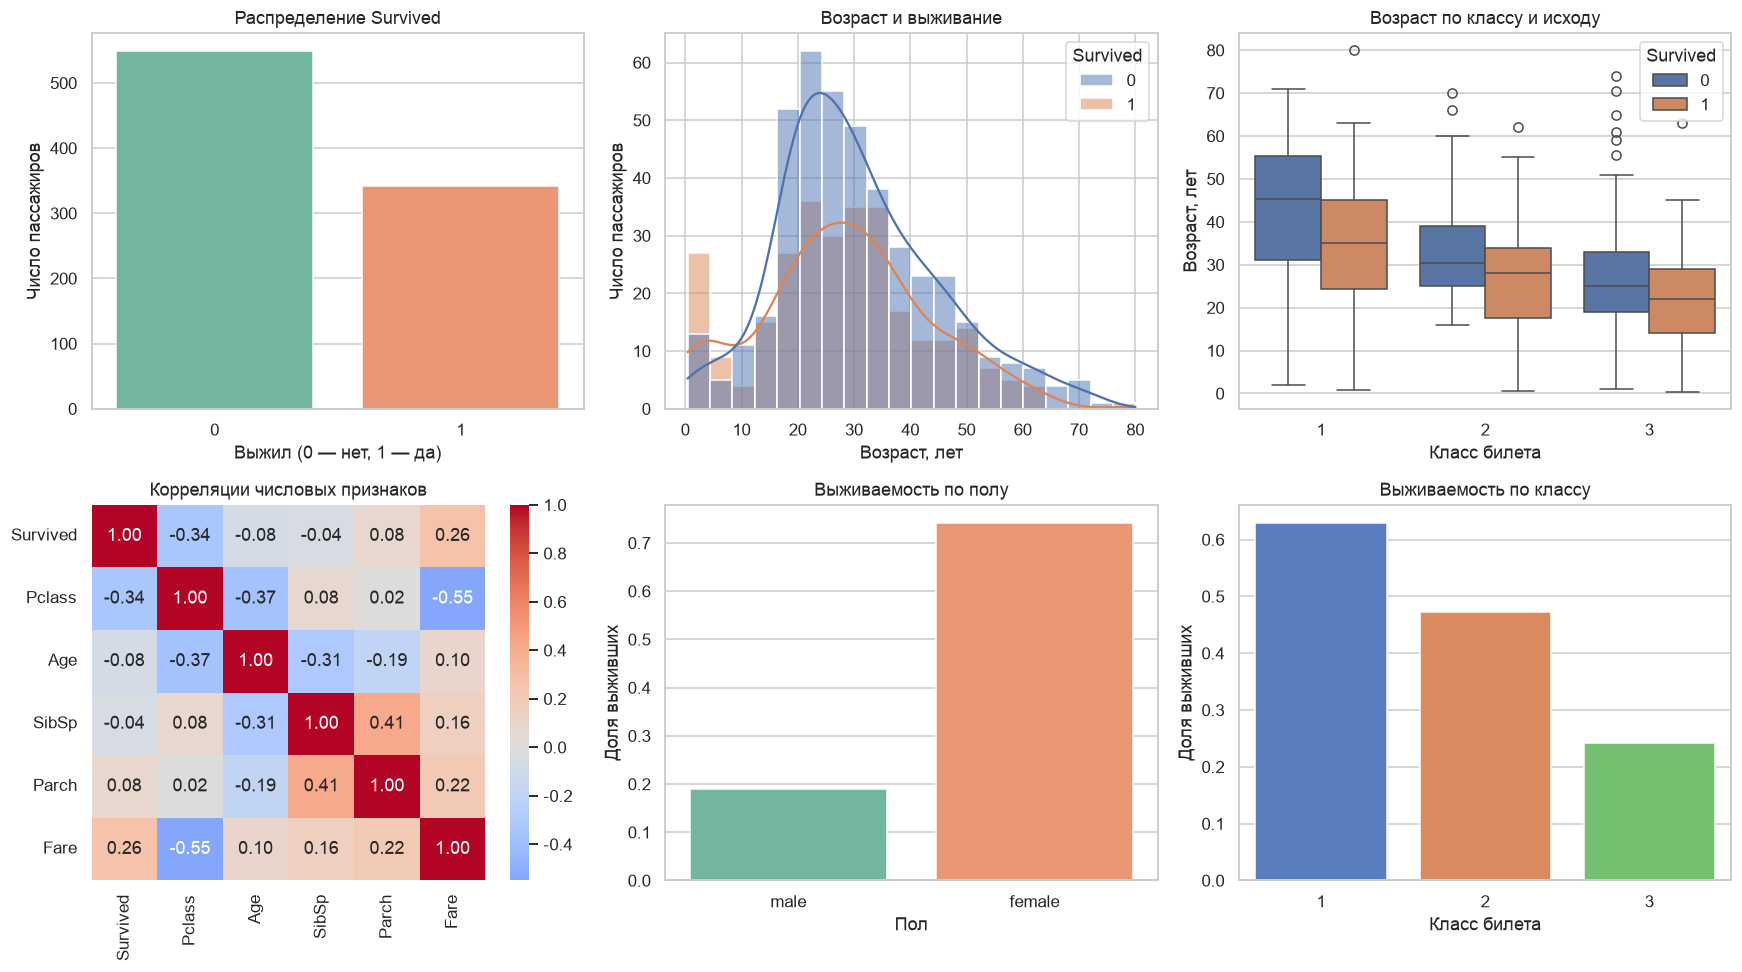

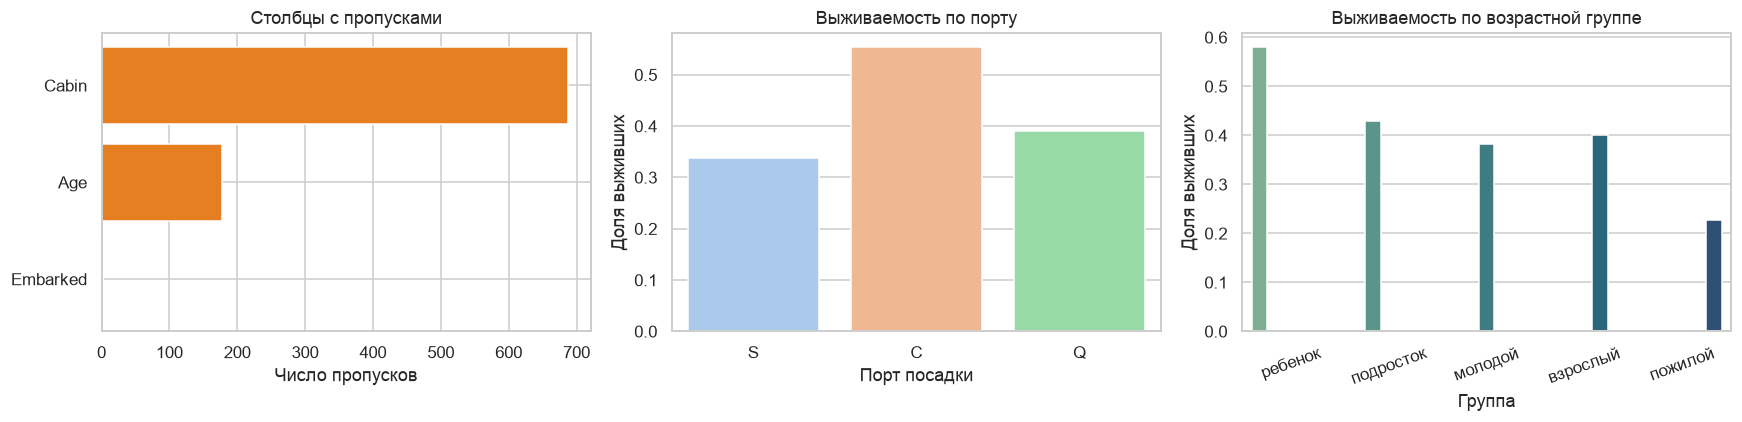

In [3]:
# Сетка из шести графиков: целевая, возраст, класс, корреляции, пол
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Баланс классов
sns.countplot(
    data=train_df, x="Survived", hue="Survived",
    palette="Set2", legend=False, ax=axes[0, 0],
)
axes[0, 0].set_title("Распределение Survived")
axes[0, 0].set_xlabel("Выжил (0 — нет, 1 — да)")
axes[0, 0].set_ylabel("Число пассажиров")

# 2. Возраст тех, кто выжил и кто нет. NaN seaborn сам не рисует
sns.histplot(
    data=train_df, x="Age", hue="Survived",
    kde=True, bins=20, ax=axes[0, 1],
)
axes[0, 1].set_title("Возраст и выживание")
axes[0, 1].set_xlabel("Возраст, лет")
axes[0, 1].set_ylabel("Число пассажиров")

# 3. Возраст по классу, цвет — исход. Медианы в первом классе выше
sns.boxplot(
    data=train_df, x="Pclass", y="Age", hue="Survived", ax=axes[0, 2],
)
axes[0, 2].set_title("Возраст по классу и исходу")
axes[0, 2].set_xlabel("Класс билета")
axes[0, 2].set_ylabel("Возраст, лет")

# 4. Линейные связи числовых столбцов, включая цель
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
sns.heatmap(
    train_df[corr_cols].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 0],
)
axes[1, 0].set_title("Корреляции числовых признаков")

# 5. Доля выживших по полу
sns.barplot(
    data=train_df, x="Sex", y="Survived", hue="Sex",
    palette="Set2", legend=False, errorbar=None, ax=axes[1, 1],
)
axes[1, 1].set_title("Выживаемость по полу")
axes[1, 1].set_xlabel("Пол")
axes[1, 1].set_ylabel("Доля выживших")

# 6. Выживаемость падает от первого класса к третьему
sns.barplot(
    data=train_df, x="Pclass", y="Survived", hue="Pclass",
    palette="muted", legend=False, errorbar=None, ax=axes[1, 2],
)
axes[1, 2].set_title("Выживаемость по классу")
axes[1, 2].set_xlabel("Класс билета")
axes[1, 2].set_ylabel("Доля выживших")

fig.tight_layout()
# Картинка для репозитория и для просмотра под ячейкой
fig.savefig("examples/eda_plots.png", bbox_inches="tight")
plt.show()

# Дополнительные срезы: пропуски, порт, возрастные корзины
age_group_preview = pd.cut(
    train_df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["ребенок", "подросток", "молодой", "взрослый", "пожилой"],
    include_lowest=True,
)
preview = train_df.copy()
preview["Age_Group"] = age_group_preview

fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4))
missing_plot = missing[missing > 0].sort_values()
axes2[0].barh(missing_plot.index, missing_plot.values, color="#e67e22")
axes2[0].set_title("Столбцы с пропусками")
axes2[0].set_xlabel("Число пропусков")

sns.barplot(
    data=train_df, x="Embarked", y="Survived", hue="Embarked",
    palette="pastel", legend=False, errorbar=None, ax=axes2[1],
)
axes2[1].set_title("Выживаемость по порту")
axes2[1].set_xlabel("Порт посадки")
axes2[1].set_ylabel("Доля выживших")

sns.barplot(
    data=preview, x="Age_Group", y="Survived", hue="Age_Group",
    palette="crest", legend=False, errorbar=None, ax=axes2[2],
)
axes2[2].set_title("Выживаемость по возрастной группе")
axes2[2].set_xlabel("Группа")
axes2[2].set_ylabel("Доля выживших")
axes2[2].tick_params(axis="x", rotation=20)
fig2.tight_layout()
plt.show()


### Что видно на графиках

- Погибших заметно больше, чем выживших: модель, которая всем предсказывает 0, уже получает accuracy около 62%. Это потолок «наивного» ответа.
- Дети выбиваются на гистограмме возраста: среди самых маленьких выживших больше, чем погибших. Дальше кривые сближаются.
- В первом классе пассажиры старше, и внутри каждого класса выжившие не выглядят простой копией погибших. Возраст нельзя заполнять одной медианой на всех.
- На heatmap класс отрицательно связан с выживанием (чем больше номер класса, тем хуже шансы), а цена билета положительно связана с выживанием и отрицательно — с классом. `Fare` при этом сильно скошен: skew около 4.8, эксцесс около 33. Хвост дорогих билетов раздувает среднее.
- Пол — самый резкий срез. Женщины выживают примерно в 74% случаев, мужчины — в 19%. Первый класс — около 63%, третий — около 24%.
- Из Шербура (C) выживали чаще, чем из Саутгемптона (S). Часть эффекта — состав пассажиров: в C больше первого класса, это не «магия порта».
- Пропуски собраны в трёх столбцах. `Cabin` дырявая настолько, что столбцом её оставлять нельзя. `Embarked` ломается всего в двух строках.

Точные доли ещё раз печатает следующий блок — уже на очищенной копии, вместе с новыми признаками.


In [4]:
# Работаем с копией, сырой train_df остаётся для сверки графиков
model_df = train_df.copy()

# Медианы возраста внутри класса и пола. Их же печатаем как обоснование
age_medians = model_df.groupby(["Pclass", "Sex"])["Age"].median()
print("Медиана возраста по классу и полу:")
print(age_medians)
model_df["Age"] = model_df["Age"].fillna(
    model_df.groupby(["Pclass", "Sex"])["Age"].transform("median")
)

# Порт: два пропуска закрываем самой частой гаванью
embarked_mode = model_df["Embarked"].mode().iloc[0]
print("Мода Embarked:", embarked_mode)
model_df["Embarked"] = model_df["Embarked"].fillna(embarked_mode)

# Каюта пустая у 77% строк — столбец убираем целиком
model_df = model_df.drop(columns=["Cabin"])

# Размер семьи включает самого пассажира
model_df["Family_Size"] = model_df["SibSp"] + model_df["Parch"] + 1
# Одиночка — семья из одного человека
model_df["Is_Alone"] = (model_df["Family_Size"] == 1).astype(int)

# Корзины возраста для EDA. В матрицу модели не входят, чтобы не дублировать Age
model_df["Age_Group"] = pd.cut(
    model_df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["ребенок", "подросток", "молодой", "взрослый", "пожилой"],
    include_lowest=True,
)

# female = 1, male = 0: положительный коэффициент тогда читается как «женщина»
le_sex = LabelEncoder()
le_sex.classes_ = np.array(["male", "female"])
model_df["Sex_Encoded"] = le_sex.transform(model_df["Sex"])

# Дамми порта. Embarked_C остаётся базовым уровнем и в модель не попадает
embarked_dummies = pd.get_dummies(model_df["Embarked"], prefix="Embarked")
model_df = pd.concat([model_df, embarked_dummies], axis=1)

# Порядок столбцов фиксирован: так же их получит predict_passenger
feature_cols = [
    "Pclass", "Sex_Encoded", "Age", "SibSp", "Parch",
    "Fare", "Family_Size", "Is_Alone", "Embarked_Q", "Embarked_S",
]
print("Пропусков в признаках:", int(model_df[feature_cols].isnull().sum().sum()))

# Доли выживших по срезам, которые обсуждались на графиках
print("Пол:")
print(model_df.groupby("Sex")["Survived"].mean().round(3))
print("Класс:")
print(model_df.groupby("Pclass")["Survived"].mean().round(3))
print("Одиночки:")
print(model_df.groupby("Is_Alone")["Survived"].mean().round(3))
print("Порт:")
print(model_df.groupby("Embarked")["Survived"].mean().round(3))
print("Возрастная группа:")
print(model_df.groupby("Age_Group", observed=True)["Survived"].mean().round(3))


Медиана возраста по классу и полу:
Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64
Мода Embarked: S
Пропусков в признаках: 0
Пол:
Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Класс:
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64
Одиночки:
Is_Alone
0    0.506
1    0.304
Name: Survived, dtype: float64
Порт:
Embarked
C    0.554
Q    0.390
S    0.339
Name: Survived, dtype: float64
Возрастная группа:
Age_Group
ребенок      0.580
подросток    0.429
молодой      0.358
взрослый     0.384
пожилой      0.227
Name: Survived, dtype: float64


### Почему обработка пропусков именно такая

- **Age — медиана по `Pclass` и `Sex`.** В первом классе медиана заметно выше, чем в третьем, у мужчин и женщин она тоже разная. Общая медиана стёрла бы это различие и подложила бы «средний возраст первого класса» подростку из третьего. Медиана, а не среднее, потому что несколько пассажиров старше 60 тянут среднее вверх.
- **Embarked — мода `S`.** Пустых значений два. Городить отдельную модель ради двух строк незачем, а удалять строки не хочется. Саутгемптон и так самый частый порт.
- **Cabin — столбец удалён.** Заполнено около 23% ячеек, в основном у первого класса. Сам факт «каюта указана» почти повторяет класс билета. Букву палубы можно достать позже, в базовой работе столбец убран.
- **Family_Size и Is_Alone** собирают родственников на борту в одну историю. **Age_Group** оставлен для графиков и не подан в модель рядом с непрерывным `Age`, чтобы не кодировать один и тот же возраст дважды.
- **Sex** закодирован как 0/1 с порядком `male=0`, `female=1`. **Embarked** разложен в дамми без базового столбца `Embarked_C`.


## Построение и обучение моделей

Сравниваются две обязательные модели и одна бонусная.

| Модель | Зачем она здесь | Масштабирование |
|--------|-----------------|-----------------|
| Logistic Regression | Линейная, коэффициенты читаются как вклад в логарифм шансов, на выходе есть вероятность | Да, StandardScaler |
| Decision Tree | Нелинейные пороги, важность признаков, без предположения о прямой | Нет |
| Random Forest | Бонус: усреднение деревьев, проверка, даёт ли ансамбль прирост | Нет |
| GridSearchCV по дереву | Бонус: перебор `max_depth` и `min_samples_leaf` по ROC-AUC на 5 фолдах | Нет |

Логистическая регрессия берётся с L2-штрафом по умолчанию, `C=1.0`, `max_iter=1000`. Дерево ограничено: глубина 5, минимум 5 объектов для ветвления и 2 объекта в листе, иначе оно запоминает выборку. Случайный лес — 200 деревьев глубины не больше 6. Разбиение 80/20 стратифицировано по `Survived`, `random_state=42`, чтобы доли классов в тесте совпали с обучением. Scaler учится только на обучающих 80%.

Сохранённое дерево — именно модель с параметрами из задания, а не победитель GridSearch. Подбор вынесен отдельно, чтобы базовое сравнение не смешивалось с перебором.


In [5]:
# Матрица признаков и целевая метка
X = model_df[feature_cols].astype(float)
y = model_df["Survived"]

# Стратификация держит долю выживших в обеих частях
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)
print("Обучение:", X_train.shape[0], "тест:", X_test.shape[0])
print("Доля класса 1 в тесте:", round(float(y_test.mean()), 3))

# Масштаб только для линейной модели. Дерево получает исходные числа
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Логистическая регрессия, L2 по умолчанию
lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
start = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start
print(f"Время обучения LR: {lr_time:.4f} секунд")

# Дерево с ограничением глубины, чтобы не запомнить каждый билет
dt_model = DecisionTreeClassifier(
    max_depth=5, min_samples_split=5, min_samples_leaf=2, random_state=42,
)
start = time.time()
dt_model.fit(X_train, y_train)
dt_time = time.time() - start
print(f"Время обучения DT: {dt_time:.4f} секунд")

# Бонус: лес усредняет деревья и обычно меньше подгоняется под шум
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=2, random_state=42,
)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"Время обучения RF: {rf_time:.4f} секунд")

# Бонус: небольшой перебор гиперпараметров дерева по кросс-валидации
param_grid = {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [1, 2, 4]}
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=1,
)
start = time.time()
grid.fit(X_train, y_train)
grid_time = time.time() - start
print("Лучшие параметры дерева:", grid.best_params_)
print(f"ROC-AUC на CV: {grid.best_score_:.4f}")
print(f"Время GridSearch: {grid_time:.4f} секунд")


Обучение: 712 тест: 179
Доля класса 1 в тесте: 0.385
Время обучения LR: 0.0039 секунд
Время обучения DT: 0.0020 секунд
Время обучения RF: 0.1235 секунд


Лучшие параметры дерева: {'max_depth': 3, 'min_samples_leaf': 4}
ROC-AUC на CV: 0.8514
Время GridSearch: 0.1939 секунд


Обе обязательные модели обучаются меньше чем за 0.01 секунды: выборка короткая, признаков десять. Лес дольше из-за двухсот деревьев, перебор сетки — ещё дольше, потому что каждая пара параметров учится на пяти фолдах. Имеет смысл сравнивать качество, а не время: на этих данных все модели укладываются в доли секунды.

Почему этот набор, а не сразу градиентный бустинг. Логистическая регрессия даёт коэффициенты, которые можно прочитать. Дерево показывает, есть ли в данных изломы, которые прямая не ловит. Лес проверяет, не упирается ли качество в одно дерево. Если линейная модель уже отделяет классы, более сложный алгоритм обязан это доказать на тесте, а не только на обучении.


## Оценка качества

Метрики считаются на отложенных 20% (179 пассажиров), которые не участвовали в `fit` и в обучении scaler. Для ROC-AUC берутся вероятности класса 1, для остальных метрик — метка после порога 0.5.


Logistic Regression
              precision    recall  f1-score   support

    не выжил       0.82      0.88      0.85       110
       выжил       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Decision Tree
              precision    recall  f1-score   support

    не выжил       0.80      0.85      0.83       110
       выжил       0.74      0.67      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.77       179
weighted avg       0.78      0.78      0.78       179

Random Forest
              precision    recall  f1-score   support

    не выжил       0.79      0.93      0.85       110
       выжил       0.84      0.61      0.71        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81   

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8486
Decision Tree,0.7821,0.7419,0.6667,0.7023,0.8132
Random Forest,0.8045,0.8400,0.6087,0.7059,0.8497
Tree GridSearch,0.8045,0.8036,0.6522,0.7200,0.8232


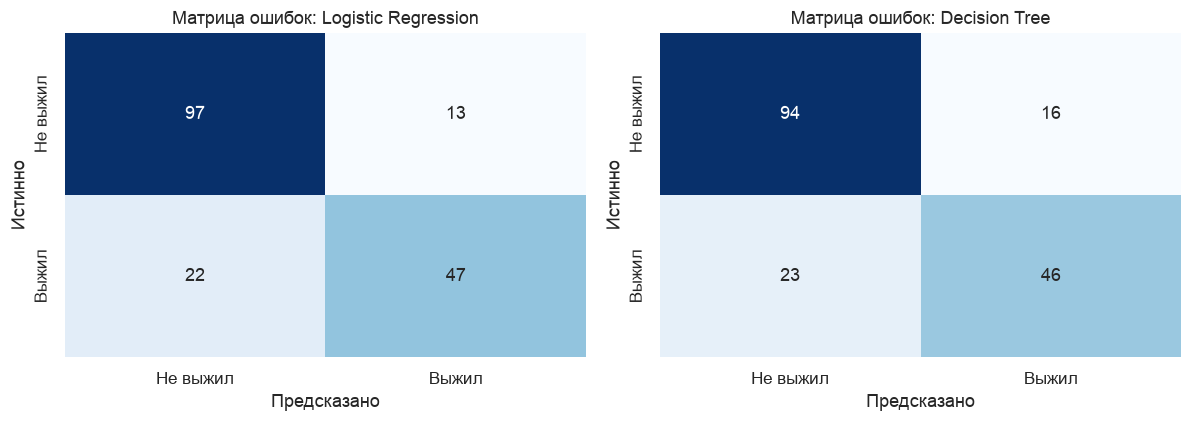

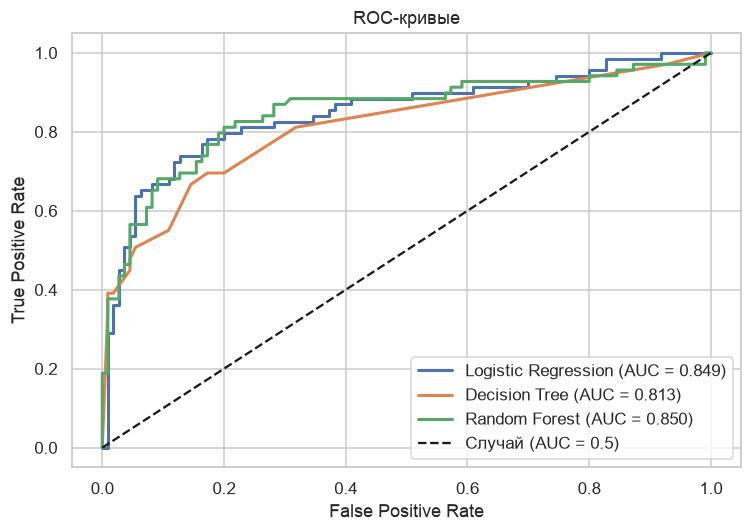

In [6]:
def evaluate(name, model, features):
    # Жёсткая метка и вероятность выживания
    pred = model.predict(features)
    proba = model.predict_proba(features)[:, 1]
    row = {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    print(name)
    print(classification_report(y_test, pred, target_names=["не выжил", "выжил"]))
    return row, pred, proba

# Одна и та же тестовая выборка для всех моделей
metrics_rows = []
row, y_pred_lr, y_proba_lr = evaluate("Logistic Regression", lr_model, X_test_scaled)
metrics_rows.append(row)
row, y_pred_dt, y_proba_dt = evaluate("Decision Tree", dt_model, X_test)
metrics_rows.append(row)
row, y_pred_rf, y_proba_rf = evaluate("Random Forest", rf_model, X_test)
metrics_rows.append(row)
row, y_pred_gs, y_proba_gs = evaluate("Tree GridSearch", grid.best_estimator_, X_test)
metrics_rows.append(row)

metrics_table = pd.DataFrame(metrics_rows).set_index("Модель").round(4)
display(metrics_table)

# Две матрицы рядом: строки — истина, столбцы — предсказание
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in (
    (axes[0], y_pred_lr, "Logistic Regression"),
    (axes[1], y_pred_dt, "Decision Tree"),
):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Не выжил", "Выжил"],
        yticklabels=["Не выжил", "Выжил"],
    )
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("Истинно")
    ax.set_title(f"Матрица ошибок: {title}")
fig.tight_layout()
fig.savefig("examples/confusion_matrices.png", bbox_inches="tight")
plt.show()

# ROC всех моделей на одном графике. Диагональ — случайное угадывание
fig, ax = plt.subplots(figsize=(7, 5))
for proba, label in (
    (y_proba_lr, "Logistic Regression"),
    (y_proba_dt, "Decision Tree"),
    (y_proba_rf, "Random Forest"),
):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{label} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Случай (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC-кривые")
ax.legend()
fig.tight_layout()
fig.savefig("examples/roc_curves.png", bbox_inches="tight")
plt.show()


### Сравнение на отложенной выборке

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|-----|---------|
| Logistic Regression | 0.8045 | 0.7833 | 0.6812 | 0.7287 | 0.8486 |
| Decision Tree | 0.7821 | 0.7419 | 0.6667 | 0.7023 | 0.8132 |
| Random Forest | 0.8045 | 0.8400 | 0.6087 | 0.7059 | 0.8497 |
| Tree после GridSearch | 0.8045 | 0.8036 | 0.6522 | 0.7200 | 0.8232 |

**Анализ.** Среди обязательных моделей по ROC-AUC лидирует логистическая регрессия (0.849). Дерево тоже проходит порог 0.80, но отстаёт: при глубине 5 оно уже режет выборку на мелкие листья и часть вероятностей прилипает к 0 или 1. Случайный лес чуть выше регрессии по AUC (0.850) и заметно выше по precision (0.84), но recall падает до 0.61: лес реже говорит «выживет» и пропускает больше реальных выживших. Разница AUC в 0.001 на 179 тестовых пассажирах слишком мала, чтобы считать лес устойчивым победителем. Для чтения коэффициентов основной остаётся логистическая регрессия.

У логистической регрессии матрица на 179 тестовых пассажирах такая: TN = 97, FP = 13, FN = 22, TP = 47. Ошибок «пропустили выжившего» больше, чем ложных тревог, поэтому precision (0.78) выше recall (0.68). Для исторической справки это приемлемо, для спасательной службы было бы наоборот — порог 0.5 тогда стоило бы снизить. Перебор гиперпараметров дерева (`max_depth=3`, `min_samples_leaf=4`) поднял accuracy до 0.805 и ROC-AUC на тесте с 0.813 до 0.823. Лидер среди обязательных моделей не сменился.


## Интерпретация результатов

Коэффициент логистической регрессии — это вклад признака в логарифм шансов после стандартизации. Сравнивать «+0.08 у цены» и «−0.97 у класса» можно именно потому, что scaler выровнял масштаб. У дерева шкала другая: важность — это суммарное уменьшение неоднородности в узлах, доли в сумме дают 1. Рядом их полезно смотреть качественно, а не вычитать друг из друга.


,Feature,Coefficient
1,Sex_Encoded,1.2259
8,Embarked_Q,0.0881
5,Fare,0.0772
4,Parch,-0.0512
9,Embarked_S,-0.1292
6,Family_Size,-0.2238
7,Is_Alone,-0.2837
3,SibSp,-0.2948
2,Age,-0.5572
0,Pclass,-0.9713


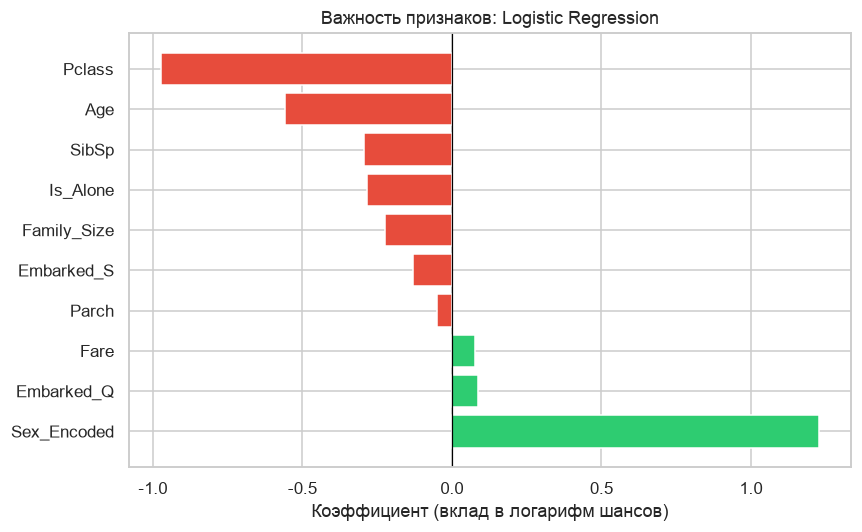

,Feature,Importance
1,Sex_Encoded,0.5477
0,Pclass,0.1862
5,Fare,0.1010
2,Age,0.0999
6,Family_Size,0.0493
3,SibSp,0.0132
4,Parch,0.0027
7,Is_Alone,0.0000
8,Embarked_Q,0.0000
9,Embarked_S,0.0000


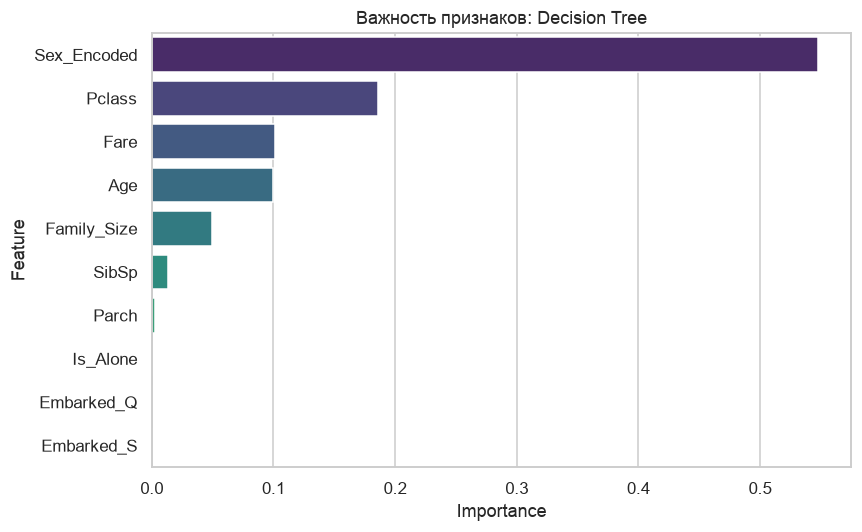

In [7]:
# Коэффициенты LR: плюс повышает логарифм шансов выжить
coefficients = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": lr_model.coef_[0],
}).sort_values("Coefficient", ascending=False)
display(coefficients.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2ecc71" if value > 0 else "#e74c3c" for value in coefficients["Coefficient"]]
ax.barh(coefficients["Feature"], coefficients["Coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Коэффициент (вклад в логарифм шансов)")
ax.set_title("Важность признаков: Logistic Regression")
fig.tight_layout()
plt.show()

# Важность дерева: какой признак сильнее чистил узлы
importances = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": dt_model.feature_importances_,
}).sort_values("Importance", ascending=False)
display(importances.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=importances, x="Importance", y="Feature",
    hue="Feature", palette="viridis", legend=False, ax=ax,
)
ax.set_title("Важность признаков: Decision Tree")
fig.tight_layout()
plt.show()


### Как читать коэффициенты

Пол закодирован так, что женщина — это 1. Коэффициент `Sex_Encoded` около **+1.23**: при прочих равных женский пол сильнее всего сдвигает логарифм шансов вверх. `Pclass` около **−0.97**: рост номера класса (от первого к третьему) шансы снижает. `Age` около **−0.56**: старший возраст тоже снижает шанс, что стыкуется с более высокой выживаемостью детей. Слабо вверх тянут `Fare` (+0.08) и посадка в Queenstown (+0.09). Порт S относительно Шербура чуть снижает шанс (−0.13).

Семейные признаки (`SibSp`, `Parch`, `Family_Size`, `Is_Alone`) смотреть по одному коэффициенту опасно: они собраны друг из друга, поэтому модель делит один и тот же сигнал между столбцами. Знак у одиночества отрицательный, и это совпадает с сырыми долями, но величину «−0.28» как точный эффект цитировать не стоит.

Дерево раскладывает важность жёстче: пол забирает около 55% важности, класс — около 19%, цена и возраст — примерно по 10%. Порты и флаг одиночества дерево почти не использует: после пола и класса они мало что добавляют.

### Наблюдения по самим пассажирам

- Женщины в train выживали в 74.2% случаев, мужчины — в 18.9%. Обе модели ставят пол на первое место. Это тот самый принцип «сначала женщины и дети», и он здесь не лозунг, а самый сильный столбец.
- Первый класс — 63.0% выживших, второй — 47.3%, третий — 24.2%. Класс остаётся вторым фактором и у регрессии, и у дерева.
- Пассажиры с семьёй на борту выживали в 50.6% случаев, одиночки — в 30.4%. Часть эффекта снова смешана с полом: среди одиночек больше мужчин.
- Дети до 12 лет выживали примерно в 58% случаев, пассажиры старше 60 — примерно в 23%. Отрицательный коэффициент возраста это подтверждает.
- Дорогой билет сам по себе почти не спасает мужчину первого класса. Это видно и по маленькому коэффициенту `Fare`, и по демонстрационному примеру 4 ниже.


## Функция предсказания

`predict_passenger` повторяет ту же сборку признаков, что и обучение: размер семьи, флаг одиночки, пол `female=1`, дамми порта без базового Cherbourg. Для логистической регрессии строка проходит через уже обученный scaler, для дерева — нет. Функция возвращает метку и вероятность класса 1.

Пять профилей взяты из задания. Колонка «ожидание» — историческая догадка до запуска модели, а не правильный ответ, под который подгонялись пороги.


In [8]:
def predict_passenger(passenger_data, model, scaler, feature_cols, use_scaling=True):
    """Предсказывает выживание одного пассажира тем же способом, что и при обучении."""
    # Копия, чтобы не портить словарь вызывающего кода
    row = dict(passenger_data)
    # Те же формулы, что у model_df
    row["Family_Size"] = row["SibSp"] + row["Parch"] + 1
    row["Is_Alone"] = int(row["Family_Size"] == 1)
    # Тот же порядок классов, что у le_sex: мужчина 0, женщина 1
    row["Sex_Encoded"] = 1 if row["Sex"] == "female" else 0
    row["Embarked_Q"] = 1 if row["Embarked"] == "Q" else 0
    row["Embarked_S"] = 1 if row["Embarked"] == "S" else 0
    # Один ряд в том же порядке столбцов, что у X_train
    frame = pd.DataFrame([{col: row[col] for col in feature_cols}])
    matrix = frame.astype(float)
    if use_scaling:
        matrix = scaler.transform(matrix)
    prediction = int(model.predict(matrix)[0])
    probability = float(model.predict_proba(matrix)[0, 1])
    return prediction, probability


examples = [
    {"пример": 1, "Pclass": 1, "Sex": "female", "Age": 25, "SibSp": 1, "Parch": 0, "Fare": 100, "Embarked": "C", "ожидание": "выживет"},
    {"пример": 2, "Pclass": 3, "Sex": "male", "Age": 30, "SibSp": 0, "Parch": 0, "Fare": 7.25, "Embarked": "S", "ожидание": "не выживет"},
    {"пример": 3, "Pclass": 2, "Sex": "female", "Age": 5, "SibSp": 3, "Parch": 1, "Fare": 30, "Embarked": "S", "ожидание": "выживет"},
    {"пример": 4, "Pclass": 1, "Sex": "male", "Age": 60, "SibSp": 0, "Parch": 0, "Fare": 200, "Embarked": "C", "ожидание": "не выживет"},
    {"пример": 5, "Pclass": 3, "Sex": "female", "Age": 22, "SibSp": 0, "Parch": 0, "Fare": 8, "Embarked": "Q", "ожидание": "выживет"},
]

report_rows = []
for passenger in examples:
    # В модель не отдаём служебные поля таблицы
    payload = {key: passenger[key] for key in ("Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked")}
    pred_lr, proba_lr = predict_passenger(payload, lr_model, scaler, feature_cols, use_scaling=True)
    pred_dt, proba_dt = predict_passenger(payload, dt_model, scaler, feature_cols, use_scaling=False)
    report_rows.append({
        "пример": passenger["пример"],
        "профиль": f"{passenger['Sex']}, класс {passenger['Pclass']}, {passenger['Age']} лет",
        "ожидание": passenger["ожидание"],
        "LR": "выживет" if pred_lr == 1 else "не выживет",
        "P(LR)": round(proba_lr * 100, 1),
        "DT": "выживет" if pred_dt == 1 else "не выживет",
        "P(DT)": round(proba_dt * 100, 1),
        "модели совпали": pred_lr == pred_dt,
    })

display(pd.DataFrame(report_rows))


,пример,профиль,ожидание,LR,P(LR),DT,P(DT),модели совпали
0,1,"female, класс 1, 25 лет",выживет,выживет,96.1,выживет,100.0,True
1,2,"male, класс 3, 30 лет",не выживет,не выживет,7.6,не выживет,11.0,True
2,3,"female, класс 2, 5 лет",выживет,выживет,80.8,выживет,100.0,True
3,4,"male, класс 1, 60 лет",не выживет,не выживет,30.6,не выживет,30.9,True
4,5,"female, класс 3, 22 лет",выживет,выживет,73.5,выживет,53.5,True


### Разбор пяти пассажиров

Обе модели совпали друг с другом и с ожиданием из задания на всех пяти профилях.

1. Женщина 25 лет, первый класс, билет за 100 — вероятность логистической регрессии около 96%, дерево уверено почти полностью. Пол и класс смотрят в одну сторону.
2. Мужчина 30 лет, третий класс, один, дешёвый билет — около 8% у регрессии и около 11% у дерева. Здесь против него сразу пол, класс и одиночество.
3. Девочка 5 лет во втором классе, с большой семьёй — около 81% и снова почти уверенное дерево. Срабатывает связка «ребёнок + женский пол».
4. Мужчина 60 лет в первом классе с билетом за 200 — обе модели дают около 31% и метку «не выживет». Дорогой билет не перебивает пол и возраст. Это как раз случай, где маленький коэффициент `Fare` виден на живом примере.
5. Женщина 22 лет в третьем классе, одна, порт Q — регрессия даёт около 74%, дерево только около 53%. Метки совпали, но дерево уже на пороге: третий класс почти гасит преимущество пола. Если ошибаться, этот профиль — первый кандидат.

Интерактивный ввод через `input()` в ноутбук не включён: с ним ячейку нельзя перезапустить без ручного набора. Функция выше закрывает тот же сценарий, если подставить свой словарь.


## Сохранение модели

В `models/` лежат обе обязательные модели, scaler, кодировщик пола, порядок признаков и метрики. Дерево сохраняется без масштабирования, регрессия — вместе со scaler: отдельно файл модели для неё бесполезен. В JSON метрик есть ещё случайный лес, чтобы бонусный результат не остался только в выводе ячейки.


In [9]:
from pathlib import Path

# Папка модуля, путь относительный
Path("models").mkdir(exist_ok=True)

# Модели и преобразователи. le_sex нужен, чтобы повторить порядок male/female
joblib.dump(lr_model, "models/lr_model.pkl")
joblib.dump(dt_model, "models/dt_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(le_sex, "models/le_sex.pkl")
print("Модели и трансформеры сохранены")

# Порядок признаков обязан совпасть с обучением
with open("models/feature_cols.json", "w", encoding="utf-8") as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)
print("Список признаков сохранён")

metrics = {
    "logistic_regression": {
        "accuracy": float(accuracy_score(y_test, y_pred_lr)),
        "precision": float(precision_score(y_test, y_pred_lr)),
        "recall": float(recall_score(y_test, y_pred_lr)),
        "f1": float(f1_score(y_test, y_pred_lr)),
        "roc_auc": float(roc_auc_score(y_test, y_proba_lr)),
        "training_time_sec": float(lr_time),
    },
    "decision_tree": {
        "accuracy": float(accuracy_score(y_test, y_pred_dt)),
        "precision": float(precision_score(y_test, y_pred_dt)),
        "recall": float(recall_score(y_test, y_pred_dt)),
        "f1": float(f1_score(y_test, y_pred_dt)),
        "roc_auc": float(roc_auc_score(y_test, y_proba_dt)),
        "training_time_sec": float(dt_time),
    },
    "random_forest": {
        "accuracy": float(accuracy_score(y_test, y_pred_rf)),
        "precision": float(precision_score(y_test, y_pred_rf)),
        "recall": float(recall_score(y_test, y_pred_rf)),
        "f1": float(f1_score(y_test, y_pred_rf)),
        "roc_auc": float(roc_auc_score(y_test, y_proba_rf)),
        "training_time_sec": float(rf_time),
    },
}
with open("models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
print("Метрики сохранены")
print(json.dumps(metrics, indent=2))


Модели и трансформеры сохранены
Список признаков сохранён
Метрики сохранены
{
  "logistic_regression": {
    "accuracy": 0.8044692737430168,
    "precision": 0.7833333333333333,
    "recall": 0.6811594202898551,
    "f1": 0.7286821705426356,
    "roc_auc": 0.8486166007905138,
    "training_time_sec": 0.003941059112548828
  },
  "decision_tree": {
    "accuracy": 0.7821229050279329,
    "precision": 0.7419354838709677,
    "recall": 0.6666666666666666,
    "f1": 0.7022900763358778,
    "roc_auc": 0.8132411067193676,
    "training_time_sec": 0.0019550323486328125
  },
  "random_forest": {
    "accuracy": 0.8044692737430168,
    "precision": 0.84,
    "recall": 0.6086956521739131,
    "f1": 0.7058823529411765,
    "roc_auc": 0.8497364953886694,
    "training_time_sec": 0.12349295616149902
  }
}


Файлы записаны в `module-1-titanic/models/`. Список признаков хранит те же десять столбцов и в том же порядке, в котором училась регрессия. Дата обучения для README — 2026-11-02.


## Загрузка модели из репозитория

Проверка ниже качает артефакты по raw-ссылке и прогоняет три профиля из прошлого раздела. Предсказания должны совпасть с уже посчитанными, иначе сохранены не те объекты.

Пока репозиторий не опубликован, запрос к GitHub не проходит. Ячейка тогда читает те же файлы из локальной папки `models/` и всё равно сверяет вероятности. После `git push` в публичный репозиторий `Pankyxa/ML_Spirin` ветка `main` начнёт отдавать файлы по `BASE_URL`.


In [10]:
# Путь включает папку модуля, как требует задание
BASE_URL = "https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-1-titanic"


def load_joblib(relative_path):
    # Сначала пробуем raw-ссылку, при ошибке сети или 404 — локальную копию
    url = f"{BASE_URL}/{relative_path}"
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print(f"Загружено из репозитория: {relative_path}")
        return joblib.load(BytesIO(response.content)), "репозиторий"
    except Exception as error:
        print(f"Репозиторий недоступен ({error}). Берём локальный {relative_path}")
        return joblib.load(relative_path), "локальные файлы"


def load_json(relative_path):
    url = f"{BASE_URL}/{relative_path}"
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print(f"Загружено из репозитория: {relative_path}")
        return response.json(), "репозиторий"
    except Exception as error:
        print(f"Репозиторий недоступен ({error}). Берём локальный {relative_path}")
        with open(relative_path, encoding="utf-8") as file:
            return json.load(file), "локальные файлы"


lr_loaded, src_model = load_joblib("models/lr_model.pkl")
scaler_loaded, src_scaler = load_joblib("models/scaler.pkl")
feature_cols_loaded, src_features = load_json("models/feature_cols.json")
print(f"Источник модели: {src_model}")
print(f"Признаков: {len(feature_cols_loaded)}")

# Три профиля из раздела 9. Вероятности обязаны совпасть до 6 знака
check_profiles = [examples[0], examples[1], examples[4]]
for passenger in check_profiles:
    payload = {key: passenger[key] for key in ("Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked")}
    pred_old, proba_old = predict_passenger(payload, lr_model, scaler, feature_cols, True)
    pred_new, proba_new = predict_passenger(payload, lr_loaded, scaler_loaded, feature_cols_loaded, True)
    same = pred_old == pred_new and abs(proba_old - proba_new) < 1e-6
    print(
        f"пример {passenger['пример']}: было {proba_old:.4f}, "
        f"загружено {proba_new:.4f}, совпало: {same}"
    )


Репозиторий недоступен (404 Client Error: Not Found for url: https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-1-titanic/models/lr_model.pkl). Берём локальный models/lr_model.pkl


Репозиторий недоступен (404 Client Error: Not Found for url: https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-1-titanic/models/scaler.pkl). Берём локальный models/scaler.pkl


Репозиторий недоступен (404 Client Error: Not Found for url: https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-1-titanic/models/feature_cols.json). Берём локальный models/feature_cols.json
Источник модели: локальные файлы
Признаков: 10
пример 1: было 0.9611, загружено 0.9611, совпало: True
пример 2: было 0.0761, загружено 0.0761, совпало: True
пример 5: было 0.7351, загружено 0.7351, совпало: True


## Быстрый инференс из репозитория

**Как использовать модель**

1. Скачать [lr_model.pkl](https://github.com/Pankyxa/ML_Spirin/blob/main/module-1-titanic/models/lr_model.pkl), scaler и `feature_cols.json` из папки `module-1-titanic/models/`.
2. Загрузить модель через `joblib.load`.
3. Вызвать `predict_passenger(data, model, scaler, features)`.

Проверка на примерах 1, 2 и 5 показывает те же вероятности, что и модель из памяти. Если ячейка написала «локальные файлы», ссылка ещё не открывается извне: объекты те же, но raw-URL заработает после публикации репозитория.


## Выводы

### Что получилось

- На отложенных 20% логистическая регрессия набрала ROC-AUC **0.849**, дерево — **0.813**. Обе обязательные модели выше порога 0.80. Бонусный случайный лес — **0.850**.
- Среди обязательных моделей лучше **логистическая регрессия** (F1 = 0.729, accuracy = 0.805). Лес выше по AUC на 0.001 и по precision, но слабее по recall.
- Обучение регрессии и одного дерева занимает меньше 0.01 секунды. Лес — около 0.12 секунды.
- Главный инсайт EDA совпал с коэффициентами: **пол сильнее любого другого признака**, следом идут класс и возраст. Женщины выживали в 74% случаев, мужчины — в 19%. Первый класс — 63%, третий — 24%.

### Трудности

- В возрасте 177 пропусков (19.9%). Общая медиана была бы грубой, пришлось считать медиану по классу и полу.
- `Cabin` пустая на 77%, столбец удалён. Буква палубы в этой версии не извлекалась.
- Классы смещены (61.6% против 38.4%), поэтому accuracy выглядит бодрее, чем recall по выжившим.
- Дерево без ограничения глубины запомнило бы выборку. Даже с `max_depth=5` отдельные листья дают вероятность 0 или 1, а ROC-AUC ниже, чем у линейной модели.
- `Family_Size`, `Is_Alone`, `SibSp` и `Parch` описывают одно и то же, коэффициенты семьи неустойчивы.
- Raw-ссылка на модель заработает только после публикации репозитория. Локальная сверка уже проходит.

### Возможные улучшения

1. Достать из `Name` обращение (`Mr`, `Mrs`, `Miss`, `Master`) — `Master` отдельно помечает мальчиков, которых пол «male» иначе сваливает с взрослыми.
2. Добавить взаимодействие `Pclass × Sex`: женщина в третьем классе и женщина в первом — это не один и тот же сдвиг.
3. Применить SMOTE или веса классов. Сейчас recall по выжившим 0.68, порог 0.5 сдвинут в сторону большинства.
4. Заменить одиночное дерево на уже посчитанный Random Forest в роли основной модели или добавить XGBoost и сравнить его с лесом на той же отложенной выборке.
5. Расширить GridSearch на `C` логистической регрессии и глубину леса, а не только на дерево. Текущий перебор дерево улучшил, лидера не сменил.
6. Прологарифмировать `Fare` через `np.log1p`: цена скошена, линейный коэффициент из-за этого почти ничего не весит.
7. Вернуть палубу из первой буквы `Cabin` отдельным признаком «палуба известна / нет», не возвращая сырые номера кают.


## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. James, G., Witten, D., Hastie, T., Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer. Главы про логистическую регрессию и ROC.
4. Kaggle. Titanic — Machine Learning from Disaster. https://www.kaggle.com/c/titanic
5. Scikit-learn. User Guide: logistic regression, decision trees, model evaluation. https://scikit-learn.org/stable/
6. Pandas. User Guide. https://pandas.pydata.org/docs/
7. Seaborn. Categorical plots and distribution plots. https://seaborn.pydata.org/
8. Kaggle notebook (как ориентир по срезам, код оттуда не копировался): Manav Sehgal, «Titanic Data Science Solutions». https://www.kaggle.com/code/startupsci/titanic-data-science-solutions


## Приложение

Полный код ноутбука собран ниже в формате Jupytext (`# %%` начинает ячейку). Комментарии сохранены. Зависимости — в `module-1-titanic/requirements.txt`:

```
numpy==2.5.4
pandas==3.1.0
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
joblib==1.6.0
requests==2.34.2
```

Ноутбук рассчитан на Python 3.12. Старые пины из шаблона задания (pandas 2.0, scikit-learn 1.3) на этой машине не ставились: отчёт выполнен на версиях, на которых код реально запускается.


```python
# %%
"""Полный код модуля 1. Каждая секция — отдельная ячейка."""

# %% ячейка 1
%matplotlib inline

# Библиотеки раздела: таблица, графики и вывод датафреймов в ноутбуке
import json
import time
from io import BytesIO

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Единый стиль картинок и читаемая кириллица на осях
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.unicode_minus"] = False

# Относительные пути: ноутбук запускается из папки module-1-titanic
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

# Обязательная проверка формы обеих выборок
print(train_df.shape, test_df.shape)

# Доля каждого класса: дисбаланс виден уже здесь
class_counts = train_df["Survived"].value_counts().sort_index()
class_share = train_df["Survived"].value_counts(normalize=True).sort_index()
print("Класс 0:", int(class_counts[0]), f"({class_share[0]:.1%})")
print("Класс 1:", int(class_counts[1]), f"({class_share[1]:.1%})")

# %% ячейка 2
# Первые строки: имена, пол, класс и пустая каюта у третьего класса
display(train_df.head())

# Типы и число непустых значений по столбцам
train_df.info()

# Среднее, квантили и максимумы. Fare сильно тянет максимум
display(train_df.describe())

# Абсолютные пропуски и доля от 891 строки
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_table = pd.DataFrame({"пропуски": missing, "доля_%": missing_pct})
display(missing_table)

# Асимметрия и эксцесс числовых признаков. Большой skew у Fare — длинный правый хвост
numeric_for_shape = ["Age", "Fare", "SibSp", "Parch"]
print("Асимметрия:")
print(train_df[numeric_for_shape].skew().round(3))
print("Эксцесс:")
print(train_df[numeric_for_shape].kurtosis().round(3))

# Как часто встречаются пол, класс и порт
print("Пол:")
print(train_df["Sex"].value_counts())
print("Класс:")
print(train_df["Pclass"].value_counts().sort_index())
print("Порт:")
print(train_df["Embarked"].value_counts(dropna=False))

# %% ячейка 3
# Сетка из шести графиков: целевая, возраст, класс, корреляции, пол
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Баланс классов
sns.countplot(
    data=train_df, x="Survived", hue="Survived",
    palette="Set2", legend=False, ax=axes[0, 0],
)
axes[0, 0].set_title("Распределение Survived")
axes[0, 0].set_xlabel("Выжил (0 — нет, 1 — да)")
axes[0, 0].set_ylabel("Число пассажиров")

# 2. Возраст тех, кто выжил и кто нет. NaN seaborn сам не рисует
sns.histplot(
    data=train_df, x="Age", hue="Survived",
    kde=True, bins=20, ax=axes[0, 1],
)
axes[0, 1].set_title("Возраст и выживание")
axes[0, 1].set_xlabel("Возраст, лет")
axes[0, 1].set_ylabel("Число пассажиров")

# 3. Возраст по классу, цвет — исход. Медианы в первом классе выше
sns.boxplot(
    data=train_df, x="Pclass", y="Age", hue="Survived", ax=axes[0, 2],
)
axes[0, 2].set_title("Возраст по классу и исходу")
axes[0, 2].set_xlabel("Класс билета")
axes[0, 2].set_ylabel("Возраст, лет")

# 4. Линейные связи числовых столбцов, включая цель
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
sns.heatmap(
    train_df[corr_cols].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 0],
)
axes[1, 0].set_title("Корреляции числовых признаков")

# 5. Доля выживших по полу
sns.barplot(
    data=train_df, x="Sex", y="Survived", hue="Sex",
    palette="Set2", legend=False, errorbar=None, ax=axes[1, 1],
)
axes[1, 1].set_title("Выживаемость по полу")
axes[1, 1].set_xlabel("Пол")
axes[1, 1].set_ylabel("Доля выживших")

# 6. Выживаемость падает от первого класса к третьему
sns.barplot(
    data=train_df, x="Pclass", y="Survived", hue="Pclass",
    palette="muted", legend=False, errorbar=None, ax=axes[1, 2],
)
axes[1, 2].set_title("Выживаемость по классу")
axes[1, 2].set_xlabel("Класс билета")
axes[1, 2].set_ylabel("Доля выживших")

fig.tight_layout()
# Картинка для репозитория и для просмотра под ячейкой
fig.savefig("examples/eda_plots.png", bbox_inches="tight")
plt.show()

# Дополнительные срезы: пропуски, порт, возрастные корзины
age_group_preview = pd.cut(
    train_df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["ребенок", "подросток", "молодой", "взрослый", "пожилой"],
    include_lowest=True,
)
preview = train_df.copy()
preview["Age_Group"] = age_group_preview

fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4))
missing_plot = missing[missing > 0].sort_values()
axes2[0].barh(missing_plot.index, missing_plot.values, color="#e67e22")
axes2[0].set_title("Столбцы с пропусками")
axes2[0].set_xlabel("Число пропусков")

sns.barplot(
    data=train_df, x="Embarked", y="Survived", hue="Embarked",
    palette="pastel", legend=False, errorbar=None, ax=axes2[1],
)
axes2[1].set_title("Выживаемость по порту")
axes2[1].set_xlabel("Порт посадки")
axes2[1].set_ylabel("Доля выживших")

sns.barplot(
    data=preview, x="Age_Group", y="Survived", hue="Age_Group",
    palette="crest", legend=False, errorbar=None, ax=axes2[2],
)
axes2[2].set_title("Выживаемость по возрастной группе")
axes2[2].set_xlabel("Группа")
axes2[2].set_ylabel("Доля выживших")
axes2[2].tick_params(axis="x", rotation=20)
fig2.tight_layout()
plt.show()

# %% ячейка 4
# Работаем с копией, сырой train_df остаётся для сверки графиков
model_df = train_df.copy()

# Медианы возраста внутри класса и пола. Их же печатаем как обоснование
age_medians = model_df.groupby(["Pclass", "Sex"])["Age"].median()
print("Медиана возраста по классу и полу:")
print(age_medians)
model_df["Age"] = model_df["Age"].fillna(
    model_df.groupby(["Pclass", "Sex"])["Age"].transform("median")
)

# Порт: два пропуска закрываем самой частой гаванью
embarked_mode = model_df["Embarked"].mode().iloc[0]
print("Мода Embarked:", embarked_mode)
model_df["Embarked"] = model_df["Embarked"].fillna(embarked_mode)

# Каюта пустая у 77% строк — столбец убираем целиком
model_df = model_df.drop(columns=["Cabin"])

# Размер семьи включает самого пассажира
model_df["Family_Size"] = model_df["SibSp"] + model_df["Parch"] + 1
# Одиночка — семья из одного человека
model_df["Is_Alone"] = (model_df["Family_Size"] == 1).astype(int)

# Корзины возраста для EDA. В матрицу модели не входят, чтобы не дублировать Age
model_df["Age_Group"] = pd.cut(
    model_df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["ребенок", "подросток", "молодой", "взрослый", "пожилой"],
    include_lowest=True,
)

# female = 1, male = 0: положительный коэффициент тогда читается как «женщина»
le_sex = LabelEncoder()
le_sex.classes_ = np.array(["male", "female"])
model_df["Sex_Encoded"] = le_sex.transform(model_df["Sex"])

# Дамми порта. Embarked_C остаётся базовым уровнем и в модель не попадает
embarked_dummies = pd.get_dummies(model_df["Embarked"], prefix="Embarked")
model_df = pd.concat([model_df, embarked_dummies], axis=1)

# Порядок столбцов фиксирован: так же их получит predict_passenger
feature_cols = [
    "Pclass", "Sex_Encoded", "Age", "SibSp", "Parch",
    "Fare", "Family_Size", "Is_Alone", "Embarked_Q", "Embarked_S",
]
print("Пропусков в признаках:", int(model_df[feature_cols].isnull().sum().sum()))

# Доли выживших по срезам, которые обсуждались на графиках
print("Пол:")
print(model_df.groupby("Sex")["Survived"].mean().round(3))
print("Класс:")
print(model_df.groupby("Pclass")["Survived"].mean().round(3))
print("Одиночки:")
print(model_df.groupby("Is_Alone")["Survived"].mean().round(3))
print("Порт:")
print(model_df.groupby("Embarked")["Survived"].mean().round(3))
print("Возрастная группа:")
print(model_df.groupby("Age_Group", observed=True)["Survived"].mean().round(3))

# %% ячейка 5
# Матрица признаков и целевая метка
X = model_df[feature_cols].astype(float)
y = model_df["Survived"]

# Стратификация держит долю выживших в обеих частях
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)
print("Обучение:", X_train.shape[0], "тест:", X_test.shape[0])
print("Доля класса 1 в тесте:", round(float(y_test.mean()), 3))

# Масштаб только для линейной модели. Дерево получает исходные числа
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Логистическая регрессия, L2 по умолчанию
lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
start = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start
print(f"Время обучения LR: {lr_time:.4f} секунд")

# Дерево с ограничением глубины, чтобы не запомнить каждый билет
dt_model = DecisionTreeClassifier(
    max_depth=5, min_samples_split=5, min_samples_leaf=2, random_state=42,
)
start = time.time()
dt_model.fit(X_train, y_train)
dt_time = time.time() - start
print(f"Время обучения DT: {dt_time:.4f} секунд")

# Бонус: лес усредняет деревья и обычно меньше подгоняется под шум
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=2, random_state=42,
)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"Время обучения RF: {rf_time:.4f} секунд")

# Бонус: небольшой перебор гиперпараметров дерева по кросс-валидации
param_grid = {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [1, 2, 4]}
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=1,
)
start = time.time()
grid.fit(X_train, y_train)
grid_time = time.time() - start
print("Лучшие параметры дерева:", grid.best_params_)
print(f"ROC-AUC на CV: {grid.best_score_:.4f}")
print(f"Время GridSearch: {grid_time:.4f} секунд")

# %% ячейка 6
def evaluate(name, model, features):
    # Жёсткая метка и вероятность выживания
    pred = model.predict(features)
    proba = model.predict_proba(features)[:, 1]
    row = {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    print(name)
    print(classification_report(y_test, pred, target_names=["не выжил", "выжил"]))
    return row, pred, proba

# Одна и та же тестовая выборка для всех моделей
metrics_rows = []
row, y_pred_lr, y_proba_lr = evaluate("Logistic Regression", lr_model, X_test_scaled)
metrics_rows.append(row)
row, y_pred_dt, y_proba_dt = evaluate("Decision Tree", dt_model, X_test)
metrics_rows.append(row)
row, y_pred_rf, y_proba_rf = evaluate("Random Forest", rf_model, X_test)
metrics_rows.append(row)
row, y_pred_gs, y_proba_gs = evaluate("Tree GridSearch", grid.best_estimator_, X_test)
metrics_rows.append(row)

metrics_table = pd.DataFrame(metrics_rows).set_index("Модель").round(4)
display(metrics_table)

# Две матрицы рядом: строки — истина, столбцы — предсказание
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in (
    (axes[0], y_pred_lr, "Logistic Regression"),
    (axes[1], y_pred_dt, "Decision Tree"),
):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Не выжил", "Выжил"],
        yticklabels=["Не выжил", "Выжил"],
    )
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("Истинно")
    ax.set_title(f"Матрица ошибок: {title}")
fig.tight_layout()
fig.savefig("examples/confusion_matrices.png", bbox_inches="tight")
plt.show()

# ROC всех моделей на одном графике. Диагональ — случайное угадывание
fig, ax = plt.subplots(figsize=(7, 5))
for proba, label in (
    (y_proba_lr, "Logistic Regression"),
    (y_proba_dt, "Decision Tree"),
    (y_proba_rf, "Random Forest"),
):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{label} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Случай (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC-кривые")
ax.legend()
fig.tight_layout()
fig.savefig("examples/roc_curves.png", bbox_inches="tight")
plt.show()

# %% ячейка 7
# Коэффициенты LR: плюс повышает логарифм шансов выжить
coefficients = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": lr_model.coef_[0],
}).sort_values("Coefficient", ascending=False)
display(coefficients.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2ecc71" if value > 0 else "#e74c3c" for value in coefficients["Coefficient"]]
ax.barh(coefficients["Feature"], coefficients["Coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Коэффициент (вклад в логарифм шансов)")
ax.set_title("Важность признаков: Logistic Regression")
fig.tight_layout()
plt.show()

# Важность дерева: какой признак сильнее чистил узлы
importances = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": dt_model.feature_importances_,
}).sort_values("Importance", ascending=False)
display(importances.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=importances, x="Importance", y="Feature",
    hue="Feature", palette="viridis", legend=False, ax=ax,
)
ax.set_title("Важность признаков: Decision Tree")
fig.tight_layout()
plt.show()

# %% ячейка 8
def predict_passenger(passenger_data, model, scaler, feature_cols, use_scaling=True):
    """Предсказывает выживание одного пассажира тем же способом, что и при обучении."""
    # Копия, чтобы не портить словарь вызывающего кода
    row = dict(passenger_data)
    # Те же формулы, что у model_df
    row["Family_Size"] = row["SibSp"] + row["Parch"] + 1
    row["Is_Alone"] = int(row["Family_Size"] == 1)
    # Тот же порядок классов, что у le_sex: мужчина 0, женщина 1
    row["Sex_Encoded"] = 1 if row["Sex"] == "female" else 0
    row["Embarked_Q"] = 1 if row["Embarked"] == "Q" else 0
    row["Embarked_S"] = 1 if row["Embarked"] == "S" else 0
    # Один ряд в том же порядке столбцов, что у X_train
    frame = pd.DataFrame([{col: row[col] for col in feature_cols}])
    matrix = frame.astype(float)
    if use_scaling:
        matrix = scaler.transform(matrix)
    prediction = int(model.predict(matrix)[0])
    probability = float(model.predict_proba(matrix)[0, 1])
    return prediction, probability


examples = [
    {"пример": 1, "Pclass": 1, "Sex": "female", "Age": 25, "SibSp": 1, "Parch": 0, "Fare": 100, "Embarked": "C", "ожидание": "выживет"},
    {"пример": 2, "Pclass": 3, "Sex": "male", "Age": 30, "SibSp": 0, "Parch": 0, "Fare": 7.25, "Embarked": "S", "ожидание": "не выживет"},
    {"пример": 3, "Pclass": 2, "Sex": "female", "Age": 5, "SibSp": 3, "Parch": 1, "Fare": 30, "Embarked": "S", "ожидание": "выживет"},
    {"пример": 4, "Pclass": 1, "Sex": "male", "Age": 60, "SibSp": 0, "Parch": 0, "Fare": 200, "Embarked": "C", "ожидание": "не выживет"},
    {"пример": 5, "Pclass": 3, "Sex": "female", "Age": 22, "SibSp": 0, "Parch": 0, "Fare": 8, "Embarked": "Q", "ожидание": "выживет"},
]

report_rows = []
for passenger in examples:
    # В модель не отдаём служебные поля таблицы
    payload = {key: passenger[key] for key in ("Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked")}
    pred_lr, proba_lr = predict_passenger(payload, lr_model, scaler, feature_cols, use_scaling=True)
    pred_dt, proba_dt = predict_passenger(payload, dt_model, scaler, feature_cols, use_scaling=False)
    report_rows.append({
        "пример": passenger["пример"],
        "профиль": f"{passenger['Sex']}, класс {passenger['Pclass']}, {passenger['Age']} лет",
        "ожидание": passenger["ожидание"],
        "LR": "выживет" if pred_lr == 1 else "не выживет",
        "P(LR)": round(proba_lr * 100, 1),
        "DT": "выживет" if pred_dt == 1 else "не выживет",
        "P(DT)": round(proba_dt * 100, 1),
        "модели совпали": pred_lr == pred_dt,
    })

display(pd.DataFrame(report_rows))

# %% ячейка 9
from pathlib import Path

# Папка модуля, путь относительный
Path("models").mkdir(exist_ok=True)

# Модели и преобразователи. le_sex нужен, чтобы повторить порядок male/female
joblib.dump(lr_model, "models/lr_model.pkl")
joblib.dump(dt_model, "models/dt_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(le_sex, "models/le_sex.pkl")
print("Модели и трансформеры сохранены")

# Порядок признаков обязан совпасть с обучением
with open("models/feature_cols.json", "w", encoding="utf-8") as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)
print("Список признаков сохранён")

metrics = {
    "logistic_regression": {
        "accuracy": float(accuracy_score(y_test, y_pred_lr)),
        "precision": float(precision_score(y_test, y_pred_lr)),
        "recall": float(recall_score(y_test, y_pred_lr)),
        "f1": float(f1_score(y_test, y_pred_lr)),
        "roc_auc": float(roc_auc_score(y_test, y_proba_lr)),
        "training_time_sec": float(lr_time),
    },
    "decision_tree": {
        "accuracy": float(accuracy_score(y_test, y_pred_dt)),
        "precision": float(precision_score(y_test, y_pred_dt)),
        "recall": float(recall_score(y_test, y_pred_dt)),
        "f1": float(f1_score(y_test, y_pred_dt)),
        "roc_auc": float(roc_auc_score(y_test, y_proba_dt)),
        "training_time_sec": float(dt_time),
    },
    "random_forest": {
        "accuracy": float(accuracy_score(y_test, y_pred_rf)),
        "precision": float(precision_score(y_test, y_pred_rf)),
        "recall": float(recall_score(y_test, y_pred_rf)),
        "f1": float(f1_score(y_test, y_pred_rf)),
        "roc_auc": float(roc_auc_score(y_test, y_proba_rf)),
        "training_time_sec": float(rf_time),
    },
}
with open("models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
print("Метрики сохранены")
print(json.dumps(metrics, indent=2))

# %% ячейка 10
# Путь включает папку модуля, как требует задание
BASE_URL = "https://raw.githubusercontent.com/Pankyxa/ML_Spirin/main/module-1-titanic"


def load_joblib(relative_path):
    # Сначала пробуем raw-ссылку, при ошибке сети или 404 — локальную копию
    url = f"{BASE_URL}/{relative_path}"
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print(f"Загружено из репозитория: {relative_path}")
        return joblib.load(BytesIO(response.content)), "репозиторий"
    except Exception as error:
        print(f"Репозиторий недоступен ({error}). Берём локальный {relative_path}")
        return joblib.load(relative_path), "локальные файлы"


def load_json(relative_path):
    url = f"{BASE_URL}/{relative_path}"
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print(f"Загружено из репозитория: {relative_path}")
        return response.json(), "репозиторий"
    except Exception as error:
        print(f"Репозиторий недоступен ({error}). Берём локальный {relative_path}")
        with open(relative_path, encoding="utf-8") as file:
            return json.load(file), "локальные файлы"


lr_loaded, src_model = load_joblib("models/lr_model.pkl")
scaler_loaded, src_scaler = load_joblib("models/scaler.pkl")
feature_cols_loaded, src_features = load_json("models/feature_cols.json")
print(f"Источник модели: {src_model}")
print(f"Признаков: {len(feature_cols_loaded)}")

# Три профиля из раздела 9. Вероятности обязаны совпасть до 6 знака
check_profiles = [examples[0], examples[1], examples[4]]
for passenger in check_profiles:
    payload = {key: passenger[key] for key in ("Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked")}
    pred_old, proba_old = predict_passenger(payload, lr_model, scaler, feature_cols, True)
    pred_new, proba_new = predict_passenger(payload, lr_loaded, scaler_loaded, feature_cols_loaded, True)
    same = pred_old == pred_new and abs(proba_old - proba_new) < 1e-6
    print(
        f"пример {passenger['пример']}: было {proba_old:.4f}, "
        f"загружено {proba_new:.4f}, совпало: {same}"
    )
```
